# Исследовательский анализ рынка заведений общественного питания Москвы

- Автор:Шварц Валерия
- Дата:31.07.2026

### Цели и задачи проекта

**Цель:** Провести анализ рынка заведений общественного питания Москвы и выбрать наиболее респектабельное место, а также направление для открытия новой точки общественного питания для инвесторов из фондов Shut Up and Take My Money .

**Задачи**:
1. Загрузить данные и познакомиться с их содержимым.
2. Провести предобработку данных.
3. Провести исследовательский анализ данных:
  - изучить данные более детально
  - изучить взаимосвязь данных в столбце `category` и `district` с другими данными
4. Сформулировать выводы по проведенному анализу.

### Описание данных

<font color='#777778'>Для анализа поступили данные из сервисов Яндекс Карты и Яндекс Бизнес за лето 2022 года. Данные состоят из двух датасетов:

- `/dat...sv` - информация о заведениях общественного питания;
- `/data...sv` -  информация о среднем чеке в заведениях общественного питания.

Описание датасета `rest_info`:

- `name` — название заведения;\
- `address` — адрес заведения;\
- `district` — административный район, в котором находится заведение, например Центральный административный округ;\
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;\
- `hours` — информация о днях и часах работы;\
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);\
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):\
0 — заведение не является сетевым;\
1 — заведение является сетевым.\
- `seats` — количество посадочных мест.\

Описание датасета `rest_price`:

- `price` — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- `avg_bill` — строка, которая хранит среднюю стоимость заказа в виде диапазона, например:\
«Средний счёт: 1000–1500 ₽»;\
«Цена чашки капучино: 130–220 ₽»;\
«Цена бокала пива: 400–600 ₽».\
и так далее;\
- `middle_avg_bill` — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»:\
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.\
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.\
Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.\
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:\
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.\
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.\
Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт..</font>


### Содержимое проекта

<font color='#777778'>1. Загрузка данных и знакомство с ними.\
2. Предобработка данных.\
3. Исследовательский анализ данных.\
4. Итоговые выводы.</font>

---

## 1. Загрузка данных и знакомство с ними


In [3]:
#Импортируем библиотеки
import pandas as pd
#Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns
#Загружаем библиотеку для расчета корреляции
from phik import phik_matrix

In [4]:
# Выгружаем данные в переменные rest_info и rest_price:
info_df = pd.read_csv('/da...sv')
price_df = pd.read_csv('/da....sv')

Познакомимся с данными датасета `rest_info` и выведем первые строки и общую информацию:

In [5]:
info_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [6]:
info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


Познакомимся с данными датасета `price_info` и выведем первые строки и общую информацию:

In [7]:
price_df.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [8]:
price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


---

### Промежуточный вывод


Датасет `rest_info` содержит 9 столбцов и 8406 строк, в которых представлена информация о заведениях общественного питания.
После первичного анализа данных можно сделать выводы:
- все данные соотвествуют описанию и выбранным типам данных. В случае необходимости можно уменьшить разряднсть бинарных значений.\
- пропуски присутсвуют в столбце `hours` и `seats`.

Датасет `price_info` содержит 5 столбцов и 4058 строк, в которых представлена информация о ценах в заведениях общественного питания.
После первичного анализа данных можно сделать выводы:
- все данные соотвествуют описанию и выбранным типам данных.
- пропуски присутсвуют во всех столбцах кроме id. Пропуски в столбцах middle_avg_bill и middle_coffee_cup не играют важной роли, в случае чего среднюю стоимость можно вычислить с помощью метода mean( ) из столбца avg_bill

### Подготовка единого датафрейма

- Объединим данные двух датасетов в один, с которыми продолжим работу.

Задача предполагает полное исследование заведений по категориям, ценам и адресам, чтобы выбрыть наиболее выигрышное место для открытия своей точки. 
Поэтому необходимо объединить данные об общественных заведениях и их ценах.

Соединять данные будем по идентификатору. Так как нам нужен полный портрет заведений, будем объединять с помощью параметра `how` со значением по умолчанию `inner`.

In [9]:
df = info_df.merge(price_df, on='id', how='left')

In [10]:
#Выводим информацию об объединённом датафрейме
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 919.4+ KB


Данные соединены и остлось 8406 строк.

## 2. Предобработка данных

Подготовим данные к исследовательскому анализу:

- Изучим корректность типов данных и при необходимости проведем их преобразование.

**Оптимизируем тип данных**

In [11]:
#Оптимизируем целочисленные типы данных
df['chain'] = pd.to_numeric(df['chain'],downcast='integer')

In [12]:
#Оптимизируем вещественные типы данных
for column in['seats','middle_avg_bill','middle_coffee_cup']:
    df[column] = pd.to_numeric(df[column], downcast='float')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int8   
 8   seats              4795 non-null   float32
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float32
 12  middle_coffee_cup  535 non-null    float32
dtypes: float32(3), float64(1), int8(1), object(8)
memory usage: 763.4+ KB


Мы сократили использование памяти столбцами `seats`,`middle_avg_bill`,`middle_coffee_cup`,`chain`.

**Проверяем наличие пропусков в данных**

Узнаем относительно и абсолютное число пропуско в столбцов объединённого датафрейма:

In [14]:
df.isna().sum().sort_values()

id                      0
name                    0
category                0
address                 0
district                0
rating                  0
chain                   0
hours                 536
seats                3611
avg_bill             4590
price                5091
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [15]:
#Подсчитываем долю пропусков
df.isna().sum()/df.shape[0]

id                   0.000000
name                 0.000000
category             0.000000
address              0.000000
district             0.000000
hours                0.063764
rating               0.000000
chain                0.000000
seats                0.429574
price                0.605639
avg_bill             0.546039
middle_avg_bill      0.625387
middle_coffee_cup    0.936355
dtype: float64

Самое большое количество пропусков составляет 93% в столбце `middle_coffee_cup`. Данные из этого столбца не сильно влияют на общий анализ информации о заведении, поэтому эти пропуски мы принимаеи решение проигнорировать. А также средние цены можно вычислить с помощью столбца `avg_bill`

На втором месте по количсетву пропусков столбец `middle_avg_bill `, 62 %, что является достаточно большим процентом.
Возможно это вызвано тем, что информация из сервиса ЯндексБизнес добавлялась пользователями и кто-то мог не знать эту информацию.Скорее всего эти данные могут помочь в анализе данных, ведь от количества посадочных мест так же может зависеть и рейтинг ресторана.

Также много пропусков в столбце `seats` - 42%.

Чтобы разобраться с причиной пропусков, обычно анализируют возможные взаимосвязи пропусков с другими данными. Для этого добавим новый столбец-признак is_seats, который укажет на наличие пропуска в столбце seats.

Если в столбце нет пропуска и в нём хранится информация, то новый столбец бцдет содержать значение 1, если в строке пропуск и информация о количестве посадочных мест отсутсвует, то столбец-признак будет содерадть значение 0.

In [16]:
def data_gap(x):
    if x:
        return 0
    return 1


In [17]:
df['is_seats'] = df['seats'].isna().apply(data_gap)

Теперь когда столбец создан, можно проверить влияние пропусков этого столбца на другие.\
- Для бинарного значения столбца `chain` и непрерывных значений найдем среднее значение mean()
- Для дискретного занчения `rating` найдём медиану

In [18]:
df.groupby('is_seats').agg({'chain':'mean',
                            'middle_avg_bill':'mean',
                            'middle_coffee_cup':'mean',
                             'rating':'median'})

,chain,middle_avg_bill,middle_coffee_cup,rating
is_seats,,,,
0,0.353919,904.238159,169.432205,4.3
1,0.401877,989.396484,178.896317,4.3


Пропуски в столбце `seats` абсолютно не влияют на рейтинг заведения, соотвественно данные пропуски можно проигнорировать. Пропуски в столбцах `middle_avg_bill`	и `middle_coffee_cup` так же можно пропустить.

In [19]:
#Проверим полные дубликаты
df.duplicated().sum()

0

В датафрейме нет полных дубликатов. Проверим неявные дубликаты по столбцам `name` и `address`.

In [20]:
df['name']=df['name'].str.lower().str.strip()

In [21]:
df['address']=df['address'].str.lower().str.strip()

In [22]:
df.duplicated(subset=['name','address']).sum()

4

В столбцах 4 дубликата, удалим их.

In [23]:
df.drop_duplicates(subset=['name','address'])

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,wowфли,кафе,"москва, улица дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN,0
1,045780ada3474c57a2112e505d74b633,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN,1
2,1070b6b59144425896c65889347fcff6,хазри,кафе,"москва, клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN,1
3,03ac7cd772104f65b58b349dc59f03ee,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,0
4,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8401,0342ad1a45ed41ba89dcba246a8267e5,суши мания,кафе,"москва, профсоюзная улица, 56",Юго-Западный административный округ,"ежедневно, 09:00–02:00",4.4,0,86.0,NaN,NaN,NaN,NaN,1
8402,ee6bb7c3650e47bd8186fca08eda1091,миславнес,кафе,"москва, пролетарский проспект, 19, корп. 1",Южный административный округ,"ежедневно, 08:00–22:00",4.8,0,150.0,NaN,NaN,NaN,NaN,1
8403,62e8c64d4c89467aba608e39ef87616b,самовар,кафе,"москва, люблинская улица, 112а, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",3.9,0,150.0,NaN,Средний счёт:от 150 ₽,150.0,NaN,1
8404,06a0db5ecd4842d48cd6350aa923e297,чайхана sabr,кафе,"москва, люблинская улица, 112а, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",4.2,1,150.0,NaN,NaN,NaN,NaN,1


Теперь осталось 8402 строки после удаления 4 дубликатов.

Проверим, какие графики работы есть в датасете.

In [24]:
df['hours'].value_counts()

ежедневно, 10:00–22:00                                               759
ежедневно, круглосуточно                                             730
ежедневно, 11:00–23:00                                               396
ежедневно, 10:00–23:00                                               310
ежедневно, 12:00–00:00                                               254
                                                                    ... 
ежедневно, 06:00–00:00                                                 1
пн-сб 10:30–21:30                                                      1
пн-пт 08:30–17:50                                                      1
пн-чт 09:00–00:00; пт 09:00–06:00; сб 11:00–06:00; вс 11:00–00:00      1
ср-вс 10:00–17:30                                                      1
Name: hours, Length: 1307, dtype: int64

Нас интересуют только заведения, которые работают ежедневно и круглосуточно, таких 730 штук.

In [25]:
df['is_24_7']=df['hours'].str.contains('ежедневно, круглосуточно')


In [26]:

df.groupby('is_24_7')['hours'].value_counts().reset_index(name='count').groupby('is_24_7').head()

,is_24_7,hours,count
0,False,"ежедневно, 10:00–22:00",759
1,False,"ежедневно, 11:00–23:00",396
2,False,"ежедневно, 10:00–23:00",310
3,False,"ежедневно, 12:00–00:00",254
4,False,"ежедневно, 09:00–21:00",204
1306,True,"ежедневно, круглосуточно",730


In [27]:
df['is_24_7'].sum()

730

Всего 730 заведений, которые работают круглосуточно.

---

### Промежуточный вывод

После предобработки данных напишите промежуточный вывод о проведённой работе. Отразите количество или долю отфильтрованных данных, если вы что-то удаляли.

После предобработки данных были приведены данные в столбцах `name` и `address` к нижнему регистру и были убраны пробелы.\
В данных нет ошибок и они хорошего качества. Также была проведена оптимизация числовых данных.
Наибольшее количество пропусков 86% в столбце `middle_coffee_cup` влияние которого не играет роли на построение общей картины заведений Москвы.

Данные были проверены на явные и неявные дубликаты, 4 неявных дубликата были удалены.

## 3. Исследовательский анализ данных
Проведем исследовательский анализ исходных данных.


---

### Задача 1

Какие категории заведений представлены в данных? Исследуйте количество объектов общественного питания по каждой категории. Результат сопроводите подходящей визуализацией.

In [28]:
#Выведем количество объектов по категориям
df['category'].value_counts()

кафе               2378
ресторан           2043
кофейня            1413
бар,паб             765
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

Результат показывает, что всего 8 категорий. При этом самой популярной является кафе - 2378 заведений, а самой не популярной - булочная - 256 заведений.

Для визуального анализа можно использовать столбчатую диаграмму.

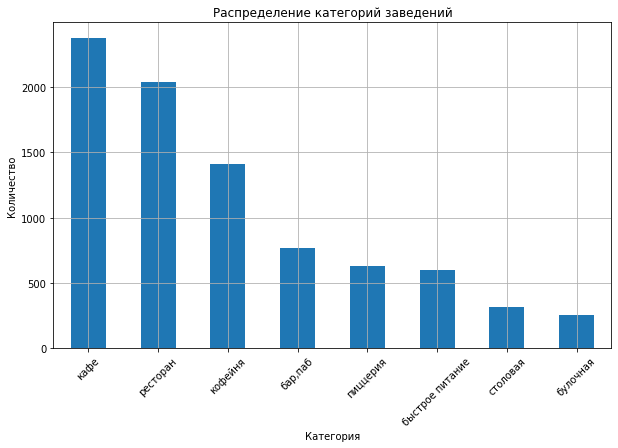

In [29]:
#Строим столбчатую диаграмму
df['category'].value_counts().plot(kind='bar', rot=45, figsize=(10,6))
plt.title('Распределение категорий заведений')
plt.xlabel('Категория')
plt.ylabel('Количество')
plt.grid()
plt.show()

---

### Задача 2

Какие административные районы Москвы присутствуют в данных? Исследуем распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. 

Выведем количество объектов по административным районам


In [30]:
df['district'].value_counts()

Центральный административный округ         2242
Северный административный округ             900
Южный административный округ                892
Северо-Восточный административный округ     891
Западный административный округ             851
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: district, dtype: int64

Самый популярный район для заведений общественного питания Центральный административный округ, там открыто 2242 заведения. 
Меньше всего заведений 409 открыто в Северо-Западном административном округе. В оствльных округах количество заведений распределено равномерно

Отразим данные на линейчатой диаграмме.

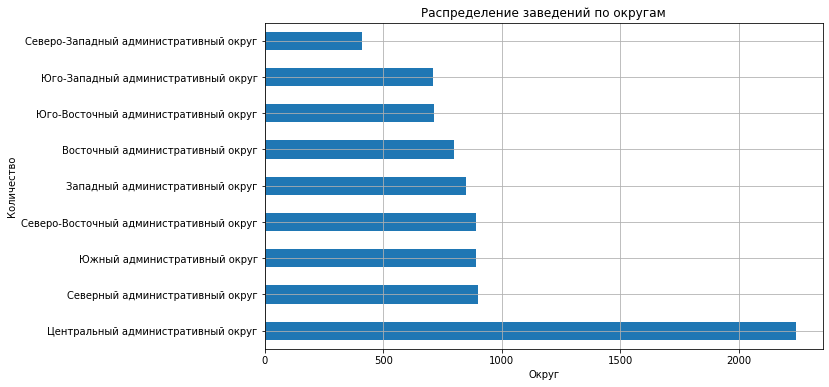

In [31]:
#Строим столбчатую диаграмму
df['district'].value_counts().plot(kind='barh', rot=0, figsize=(10,6))
plt.title('Распределение заведений по округам')
plt.xlabel('Округ')
plt.ylabel('Количество')
plt.grid()#Сетка
plt.show()

Посмотрим отдельно распределение по категориям в Центральном административном округе.

In [32]:
df.loc[df['district']=='Центральный административный округ','category'].value_counts()

ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: category, dtype: int64

Отобразим распределение категорий в Центральном административном округе с помощью столбчатой диаграммы.

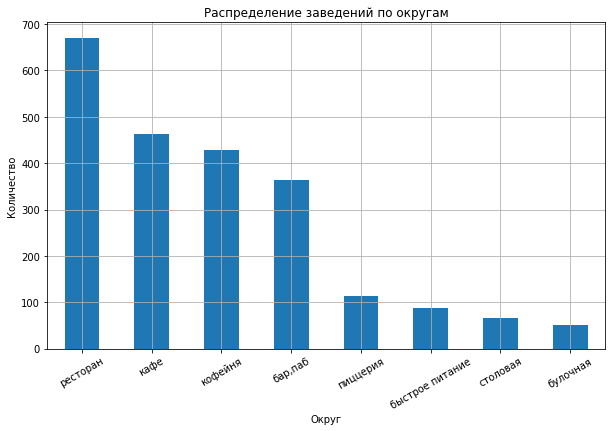

In [33]:
#Строим столбчатую диаграмму
df.loc[df['district']=='Центральный административный округ','category'].value_counts().plot(kind='bar', rot=30, figsize=(10,6))
plt.title('Распределение заведений по округам')
plt.xlabel('Округ')
plt.ylabel('Количество')
plt.grid()
plt.show()

В центральном округе больше всего заведений категории "ресторан". Составляет 670 шт. Меньше всего так же булочных, их всего 50 заведений.

---

### Задача 3

Изучим соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Каких заведений больше — сетевых или несетевых? Какие категории заведений чаще являются сетевыми?

Изучим соотношение сетевых и несетевых заведений в целом.

In [34]:
df['chain'].value_counts(normalize=True).reset_index()

,index,chain
0,0,0.618725
1,1,0.381275


Количество несетевых заведений составляет 61%. Визуализируем данные.

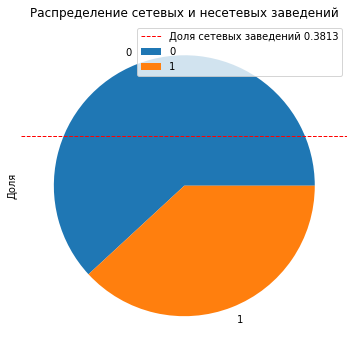

In [35]:
#Строим столбчатую диаграмму
df['chain'].value_counts(normalize=True).plot(kind='pie',
                                              figsize=(10,6), 
                                              legend=True, 
                                              rot=0,
                                              xlabel='0-несетевой,1-сетевой',
                                              title='Распределение сетевых и несетевых заведений',
                                              ylabel='Доля')
plt.grid()
# Рассчитываем среднее значение по доле сетевых заведений
mean_chain_share = df['chain'].mean()

# Наносим на график линию со средним значением доли нелояльных клиентов
plt.axhline(mean_chain_share, 
            color='red', 
            linestyle='--', 
            linewidth=1, 
            label=f'Доля сетевых заведений {round(mean_chain_share,4)}')
plt.legend()
plt.show()

Изучим соотношение сетевых и несетевых заведений в целом в разрезе категорий.

In [36]:
group_chain=df.groupby('category')['chain'].value_counts(normalize=True)

Отоборазим соотношение на графике.

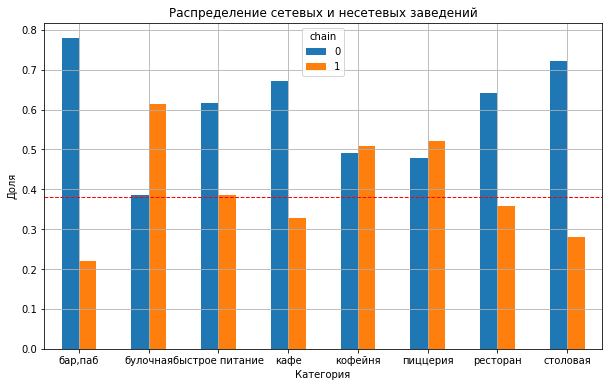

In [37]:
#Строим столбчатую диаграмму
df.groupby('category')['chain'].value_counts(normalize=True).unstack(fill_value=0).plot(kind='bar',
                                              figsize=(10,6), 
                                              legend=True, 
                                              rot=0,
                                              xlabel='Категория',
                                              title='Распределение сетевых и несетевых заведений',
                                              ylabel='Доля')
plt.grid()
# Рассчитываем среднее значение по доле сетевых заведений
mean_chain_share = df['chain'].mean()

# Наносим на график линию со средним значением доли сетевых заведений
plt.axhline(mean_chain_share, # Данные, по которым строится линия
            color='red', # Цвет линии
            linestyle='--', # Стиль линии
            linewidth=1, # Ширина линии
            label=f'Доля сетевых заведений {round(mean_chain_share,4)}')
plt.show()

Из графика и из ранее проведенного соотношения следует, что больше самый высокий процент сетевых заведений относятся к категории Булочная (61 % - сетевых, 39% несетевых заведений)

Визуализируем, какие заведения чаще являются сетевыми с помощью столбчатой диаграммы.

In [38]:
category_chain = df.groupby('category')['chain'].mean().sort_values(ascending=False)
category_chain_df=category_chain.reset_index()
category_chain_df

,category,chain
0,булочная,0.613281
1,пиццерия,0.521327
2,кофейня,0.509554
3,быстрое питание,0.384743
4,ресторан,0.357318
5,кафе,0.327586
6,столовая,0.279365
7,"бар,паб",0.220915


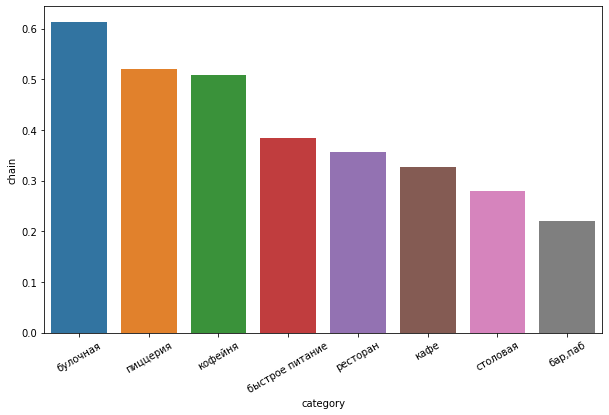

In [39]:
plt.figure(figsize=(10,6))
sns.barplot(x='category',y='chain',data=category_chain_df)
plt.xticks(rotation=30)
plt.show()

Категория заведения "Булочная" чаще является сетевой 61% против 39% несетевой, режде всего сетевыми являются "бар/паб" - 22% сетевых против 78% несетевых. 

---

### Задача 4

Исследуем количество посадочных мест в заведениях. Встречаются ли в данных аномальные значения или выбросы? Если да, то с чем они могут быть связаны? 

In [40]:
df['seats'].value_counts().sort_values(ascending=False)

40.0     253
100.0    213
60.0     175
50.0     168
80.0     160
        ... 
308.0      1
326.0      1
229.0      1
161.0      1
33.0       1
Name: seats, Length: 229, dtype: int64

Так как количество уникальных мест в заведениях равняется 208, построим гистограмму, для того, чтобы выявить, какое количество мест встречается чаще всего в заведениях, а какие значения аномальные.

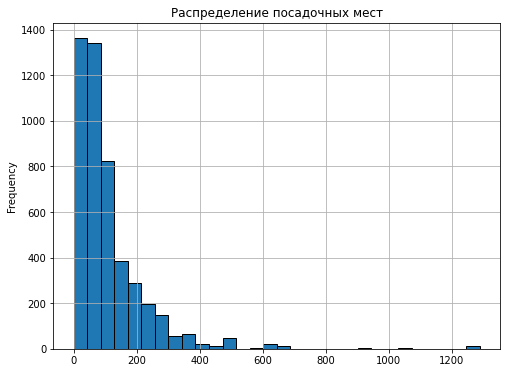

In [41]:
#Создаём контейнер графика и задаём размеры
plt.figure(figsize=(8,6))
#Строим гистограмму 
df['seats'].plot(kind='hist',#Тип графика - гисторгамма,
                bins=30,#Количество корзин
                edgecolor='black', 
                title='Распределение посадочных мест',
                xlabel='Количество мест',
                ylabel='Частота')
plt.grid()
plt.show()

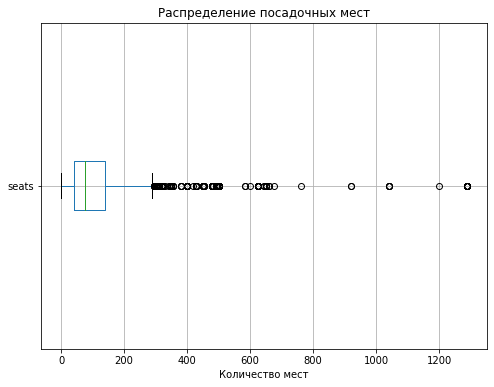

In [42]:
#Строим диаграмму размаха
#Создаем контейнер графика
plt.figure(figsize=(8,6))
#Строим диаграмму
df.boxplot(column='seats', vert=False)
#Добавляем заголовок и название оси Х
plt.title('Распределение посадочных мест')
plt.xlabel('Количество мест')
#Выводим диаграмму
plt.show()


Чаще всего встречаются значения количества мест от 20 до 120, есть аномальные значения колиства мест больше 500. Скорее всего это связано с ошибкой заполнения данных.

In [43]:
#Определяем наиболее часто встречающееся значения
median_group=df.groupby('category')['seats'].median().reset_index().sort_values('seats').round()
median_group

,category,seats
1,булочная,50.0
5,пиццерия,55.0
3,кафе,60.0
2,быстрое питание,65.0
7,столовая,76.0
4,кофейня,80.0
0,"бар,паб",82.0
6,ресторан,86.0


Типичное количество посадочных мест в ресторанах - 86, что является самым большим количеством. Самым маленьким типичным количеством посадочных мест облдает категории бар/паб - 50 мест. Визуализируем данные с помощью столбчатой диаграммы.


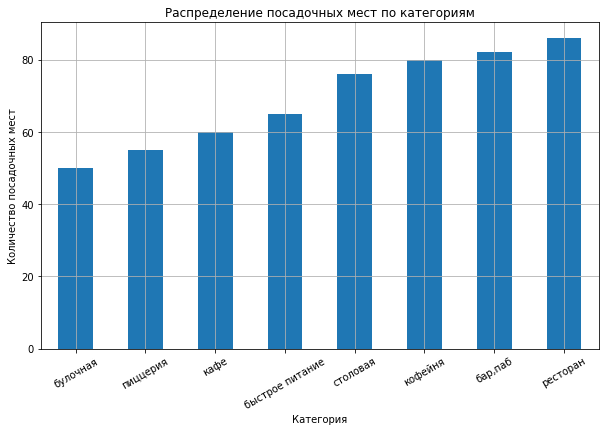

In [44]:
#Строим столбчатую диаграмму
median_group.plot(kind='bar',
          x='category',
          figsize=(10,6), 
          rot=30,
          legend=False,
          xlabel='Категория',
          title='Распределение посадочных мест по категориям',
          ylabel='Количество посадочных мест')
plt.grid()

plt.show()

---

### Задача 5

Исследуем рейтинг заведений. Визуализируем распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги для разных типов общепита?

Исследуем у какой категории самый высокий средний рейтинг.

In [45]:
mean_raiting=round(df.groupby('category')['rating'].mean(),2).sort_values(ascending=False)
mean_raiting

category
бар,паб            4.39
пиццерия           4.30
ресторан           4.29
кофейня            4.28
булочная           4.27
столовая           4.21
кафе               4.12
быстрое питание    4.05
Name: rating, dtype: float64

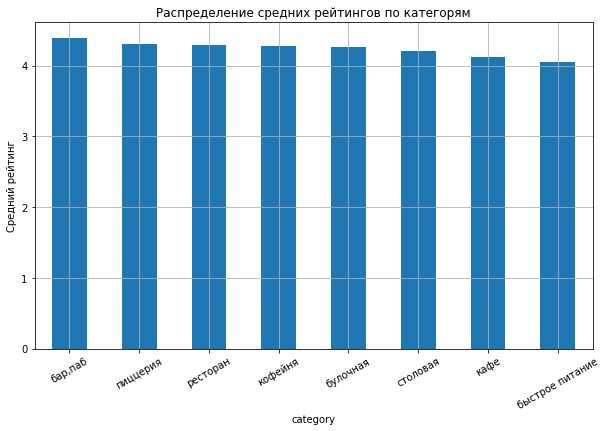

In [46]:
#Сторим столбчатую диаграмму
#Создаем контейнер графика
plt.figure(figsize=(10,6))
#Создаем диаграмму
mean_raiting.plot(kind='bar',
                 rot=30)
#Добавляем заголовок и название оси У
plt.title('Распределение средних рейтингов по категорям')
plt.ylabel('Средний рейтинг')
#Выводим сетку
plt.grid()
#Выводим график
plt.show()

На диаграмме видно, что все заведения имеют почти одинаковый средний рейтинг, но на первом месте по рейтингу находятся заведения категории бар, паб со средним рейтингом 4,39. Ниже всего рейтинг у категории заведения "быстрое питание" 4,05.


---

### Задача 6

Изучим, с какими данными показывают самую сильную корреляцию рейтинги заведений? Построим и визуализируем матрицу корреляции рейтинга заведения с разными данными: его категория, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным. Выберем самую сильную связь и проверим её.

In [47]:
#Вычисляем корреляцию
corr=df[['district','category','is_24_7','chain','seats','price','rating']].phik_matrix()
print('Корреляционная маска для переменной rating')
rating_corr=corr.loc[corr.index != 'rating'][['rating']].sort_values(by='rating', ascending=False)
rating_corr

interval columns not set, guessing: ['chain', 'seats', 'rating']
Корреляционная маска для переменной rating


,rating
price,0.220295
district,0.200691
category,0.190003
is_24_7,0.174699
chain,0.108092
seats,0.000000


Наибольшая корреляция рейтинга наблюдается с ценой в заведении (0.22), с местоположением (0.2) с категорией (0.19). Корреляция рейтинга с количеством посадочных мест не наблюдается.

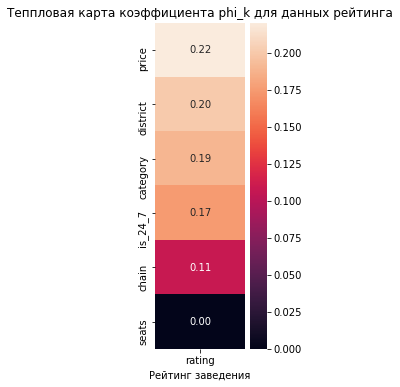

In [48]:
#Строим тепловую карту
#Настраиваем контейнер для тепловой карты
plt.figure(figsize=(2,6))

sns.heatmap(rating_corr,
            annot=True,#Обозначаем численные значения в ячейках
            fmt='.2f'#Форматируем значения:оставляем 2 знака после запятой
           )
#Добавляем заголовок и название оси Х
plt.title('Теппловая карта коэффициента phi_k для данных рейтинга')
plt.xlabel('Рейтинг заведения')
#Выводим карту
plt.show()
        

Самая сильная связь с ценой, проверим её, построив диаграмму размаха.

<Figure size 720x432 with 0 Axes>

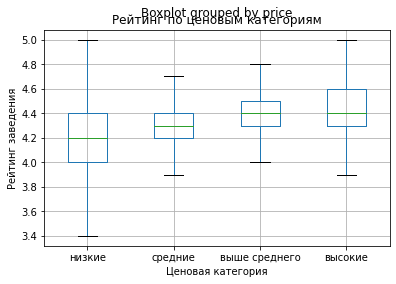

In [49]:
#Сортируем по цене
price_order = ['низкие', 'средние', 'выше среднего','высокие']
df['price'] = pd.Categorical(df['price'], categories=price_order, ordered=True)
df_sorted = df.sort_values('price')
#Строим диаграмму размаха
#Создаем контейнер графика
plt.figure(figsize=(10,6))
#Строим диаграмму
df_sorted.boxplot(column='rating', by='price',showfliers = False)
#Добавляем заголовок и название оси Х
plt.title('Рейтинг по ценовым категориям')
plt.xlabel('Ценовая категория')
plt.ylabel('Рейтинг заведения')           
#Выводим диаграмму
plt.show()

По диграмме действително видно, что есть корреляция, так как с повышением ценовой категории растёт и рейтинг.

---

### Задача 7

Сгруппируем данные по названиям заведений и найдем топ-15 популярных сетей в Москве. Для них посчитаем значения среднего рейтинга. Под популярностью понимается количество заведений этой сети в регионе. К какой категории заведений они относятся? Результат сопроводим подходящими визуализациями.

In [50]:
#Группируем данные по сетевым заведениям
chain_store=df[df['chain']==1]
#Выводим топ-15 сетевых заведений
top_15=chain_store['name'].value_counts().head(15).index

In [51]:
#Считаем средний рейтинг каждого заведения
result=chain_store[chain_store['name'].isin(top_15)].groupby('name').agg(count=('name', 'count'),
    avg_rating=('rating', 'mean'),
    category=('category','first')
).reset_index().sort_values('count', ascending=False)#Сортируем по убыванию количества заведений

round(result,2)

,name,count,avg_rating,category
13,шоколадница,120,4.18,кофейня
6,домино'с пицца,76,4.17,пиццерия
5,додо пицца,74,4.29,пиццерия
2,one price coffee,71,4.06,кофейня
14,яндекс лавка,69,3.87,ресторан
1,cofix,65,4.08,кофейня
3,prime,50,4.12,ресторан
11,хинкальная,44,4.32,быстрое питание
7,кофепорт,42,4.15,кофейня
8,кулинарная лавка братьев караваевых,39,4.39,кафе


Построим графики по количеству и рейтингу заведений

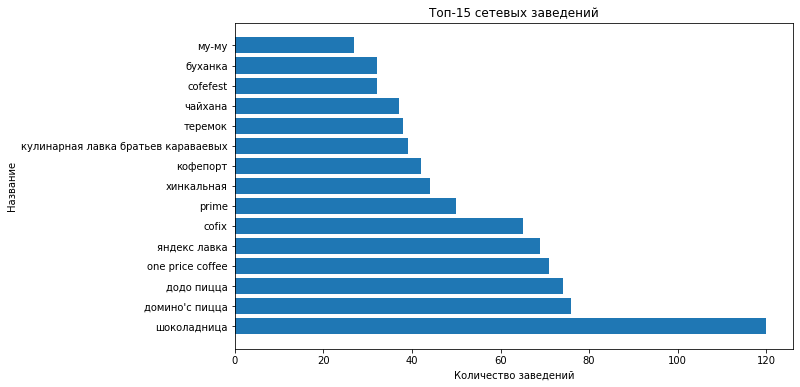

In [52]:
#Строим столбчатую диаграмму количество/название
plt.figure(figsize=(10,6))
plt.barh(result['name'],result['count'])
plt.title('Топ-15 сетевых заведений')
plt.ylabel('Название')
plt.xlabel('Количество заведений')
plt.show()

<Figure size 864x576 with 0 Axes>

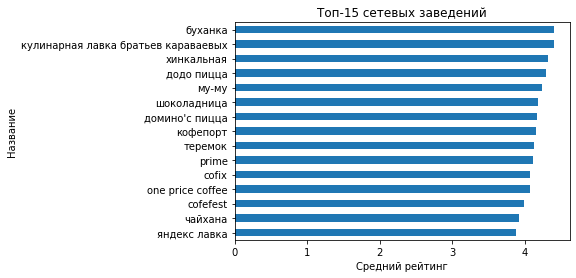

In [53]:
avg_rating_sorted=result.sort_values('avg_rating', ascending=True)
#Сторим диаграмму средний рейтинг/навзание
plt.figure(figsize=(12,8))
avg_rating_sorted.plot(kind='barh',x='name',y='avg_rating',legend=False)
plt.title('Топ-15 сетевых заведений')
plt.ylabel('Название')
plt.xlabel('Средний рейтинг')
plt.show()

Из представленных графиков можно выделить лидеров:
- по рейтингу: Булочная "Буханка" 4.40, кафе "Кулинарная лавка братьев Караваевых" 4.39, быстрое питание "Хинкальная" 4.32;
- по количеству заведений: кофейня "Шоколадница" 120 заведений, пиццерия "Доминос пицца" 76 заведений, пиццерия "Додо пицца" 74 заведений

---

### Задача 8

Изучим вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируем цены в Центральном административном округе и других. Как удалённость от центра влияет на цены в заведениях? Результат сопроводим подходящими визуализациями.


In [54]:
middle_avg=df.groupby('district')['middle_avg_bill'].agg(['count', 'mean', 'min', 'max', 'median']).round()
middle_avg

,count,mean,min,max,median
district,,,,,
Восточный административный округ,260,821.0,50.0,10000.0,575.0
Западный административный округ,306,1053.0,50.0,5250.0,1000.0
Северный административный округ,322,928.0,130.0,11000.0,650.0
Северо-Восточный административный округ,301,717.0,50.0,4500.0,500.0
Северо-Западный административный округ,157,822.0,120.0,2900.0,700.0
Центральный административный округ,1060,1191.0,0.0,7250.0,1000.0
Юго-Восточный административный округ,194,654.0,30.0,3750.0,450.0
Юго-Западный административный округ,235,793.0,100.0,2750.0,600.0
Южный административный округ,314,834.0,100.0,35000.0,500.0


Посмторим линейчатую диаграмму зависимости среднего чека от округа.

<Figure size 720x576 with 0 Axes>

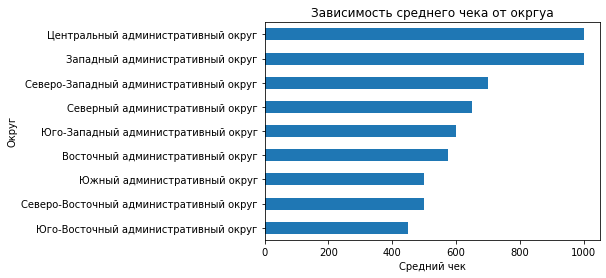

In [55]:
#Сортируем по возрастанию среднечго чека
middle_avg_sorted = middle_avg.sort_values('median', ascending=True)
#Настраиваем контейнер
plt.figure(figsize=(10,8))
#Строим диаграмму
middle_avg_sorted.plot(kind='barh', y='median', legend=False)
plt.title('Зависимость среднего чека от окргуа')
plt.ylabel('Округ')
plt.xlabel('Средний чек')
plt.show()


        Из графика видно, что самый высокий средний чек у Центрального и Западного административного округа 1000 рублей.

---

### Промежуточный вывод


Самой популярной категорией является ресторан, а самой не популярной - булочная. Самый популярный район для заведений общественного питания Центральный административный округ, там открыто 1361 заведение. Меньше всего заведений (198) открыто в Северо-Западном административном округе.

Количество несетевых заведений составляет 61%. Больше всего сетевых заведений из категории "Булочная". Рейтинг у заведений не имеет сильных различий.

Ретинг заведения зависит от цены, категории заведения и района расположения. Чем ближе заведение расположено к центру, тем выше цена.

## 4. Итоговый вывод и рекомендации
В ходе проведения исследовательского анадиза данных было проанализировано 8402 заведения, данные включали в себя инфорацию о заведениях Москвы, их название, расположение, а также цены. Акцент исследования был на том, чтобы выявить, какое месторасположение, категория заведения являются самыми популярными.

### Главный вывод
Самым популярным заведением явлеяется кафе, его количество составляет 2378, в то время, как булочных - самых непопулярных катеорий - всего 256 заведений. Округом, где больше всего расположено заведений общественного питания является Центральный административный округ, а также там и выше всего средний чек, что является логичным, так как в центральных районах всегда самая высокая проходимость.
В отношении сетевых или несетвых заведений выигрывают несетевые:  61% несетвых и 39% сетевых заведений.
Средний рейтинг у всех заведений примерно одинаковый, но он имеет зависимость от цены и категории заведения. Чуть выше, чем у остальных заведений рейтинг у заведений категории "Бар, паб"
### Рекомендации
В качестве рекомендации, стоит обратить внимание на открытие заведения в Центральном административном округе, так как там имеется высокий спрос и больше проходимость. Популярностью пользуются рестораны и кафе.

Я рекомендую для размещения Центральный администртивный округ, он является более выгодным, так как там уже размещено 2242 заведения. Также в этом округе один из самых высоких средних чеков у заведений 1000 рублей, такой же средний чек только в Западном административном округе, все остальные значения ниже.

Из категорий заведений самым востребованным по Москве является "кафе", их количество 2378, на следующем месте категория "ресторан" - 2043 заведения, Менее актуальными являются булочные, их количество 256.
Если рассматривать только Центарльный административный округ, то там самой популярной является категория "ресторан" - 670 заведений, а кафе уже меньше - 464 заведения, но кафе все равно находится на втором месте по популярности. 

По количеству типичных посадочных мест для ресторана потрубется больше - 86 штук, а в кафе количество поадочных мест в среднем 60, соотвественно затрат на открытие заведения категории "ресторан" потребуется больше.

Больше всего сетевых заведений у категории "Булочная" 61%, но их меньше всего по количеству и рейтинг у булочных не самый высокий из всех предложенных категорий и составляет 4.27 из чего можно сделать вывод, что открытие сетевого заведения не является самым выгодным и прибыльным.

Взаимосвязь между тем, является ли заведение круглосуточным и его рейтингом практически не наблюдается, поэтому не имеет значение, будет заведение круглосуточным или нет.